# Transformaciones sobre la imagen de Lena

En este cuaderno aplico a la imagen de Lena las transformaciones que pide la actividad: rotarla, sacar el negativo, umbralizarla, ecualizarla y quitarle el ruido.

Lo he hecho con un entorno de conda llamado vision, con OpenCV, NumPy, Matplotlib y Seaborn. La imagen Lena.png tiene que estar en la misma carpeta que el cuaderno.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 0. Cargar la imagen

Leo la imagen con OpenCV, que la carga en BGR, así que la paso a RGB para verla bien con Matplotlib. Casi todo lo hago sobre la imagen en escala de grises, por eso también la convierto a gris.

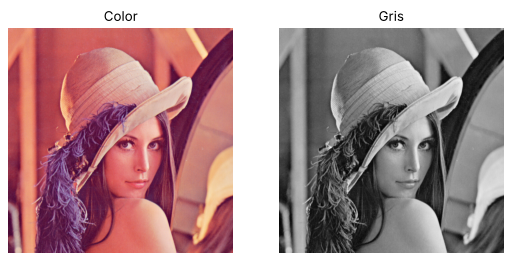

In [2]:
img_bgr = cv2.imread("./Lena.png", cv2.IMREAD_COLOR)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

fig, ax = plt.subplots(1,2,figsize=(8,4))
ax[0].imshow(img_rgb); ax[0].set_title("Color")
ax[1].imshow(gris, cmap="gray"); ax[1].set_title("Gris")
for x in ax:
    x.axis('off')
plt.show()

In [3]:
a = np.array(gris)
print(type(a))
print("shape: ", a.shape)
print("dtype: ", a.dtype)
print("min ", a.min())
print("max ", a.max())
print("media ", a.mean())
print("std ", a.std())

<class 'numpy.ndarray'>
shape:  (512, 512)
dtype:  uint8
min  25
max  245
media  124.0485610961914
std  47.855599631086996


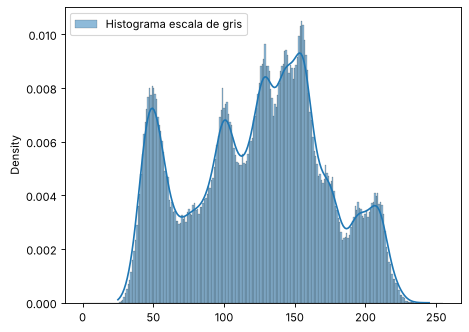

In [4]:
sns.histplot(gris.ravel(), bins=256, binrange=(0,255), stat="density", kde=True, label="Histograma escala de gris")
plt.legend()
plt.show()

Los valores van de 25 a 245, así que la imagen no usa todo el rango de 0 a 255. Esto se nota luego al ecualizar.

## 1. Imagen rotada

La rotación de un ángulo Ω se escribe como:

B(i', j') = B(i·cosΩ − j·senΩ, i·senΩ + j·cosΩ) = A(i, j)

En OpenCV se hace con getRotationMatrix2D, que crea la matriz de giro respecto al centro que le digamos, y con warpAffine, que la aplica a toda la imagen. El ángulo va en grados y si es positivo gira en sentido antihorario.

In [5]:
alto, ancho = gris.shape
centro = (ancho/2, alto/2)

angulo = 30
M = cv2.getRotationMatrix2D(centro, angulo, 1.0)
print(M)
print("cos: ", np.cos(np.radians(angulo)))
print("sen: ", np.sin(np.radians(angulo)))

[[  0.8660254    0.5        -93.70250337]
 [ -0.5          0.8660254  162.29749663]]
cos:  0.8660254037844387
sen:  0.49999999999999994


En la matriz salen el coseno y el seno igual que en la fórmula. La última columna es una traslación para que gire respecto al centro y no respecto a la esquina de arriba a la izquierda.

Para ver qué hace OpenCV por dentro también la programo con la fórmula, de dos formas. En la directa cojo cada píxel de la original y lo llevo a su nueva posición. En la inversa recorro la imagen nueva y busco de qué píxel de la original viene cada uno, girando al revés.

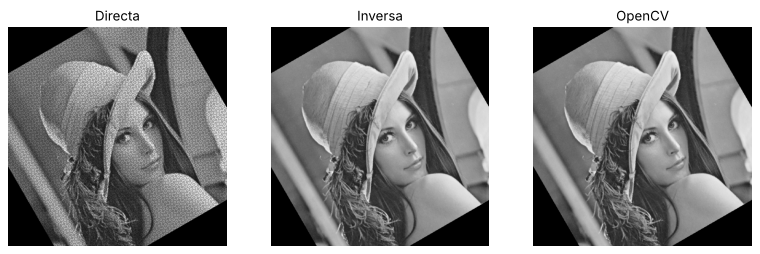

In [6]:
ang = np.radians(30)
c = np.cos(ang)
s = np.sin(ang)
ci = alto/2
cj = ancho/2

rot_directa = np.zeros_like(gris)
rot_inversa = np.zeros_like(gris)

for i in range(alto):
    for j in range(ancho):
        x = j - cj
        y = i - ci
        # directa
        j2 = int(round(c*x + s*y + cj))
        i2 = int(round(-s*x + c*y + ci))
        if 0 <= i2 < alto and 0 <= j2 < ancho:
            rot_directa[i2, j2] = gris[i, j]
        # inversa
        j1 = int(round(c*x - s*y + cj))
        i1 = int(round(s*x + c*y + ci))
        if 0 <= i1 < alto and 0 <= j1 < ancho:
            rot_inversa[i, j] = gris[i1, j1]

rot_cv = cv2.warpAffine(gris, M, (ancho, alto), flags=cv2.INTER_NEAREST)

fig, ax = plt.subplots(1,3,figsize=(12,4))
ax[0].imshow(rot_directa, cmap="gray"); ax[0].set_title("Directa")
ax[1].imshow(rot_inversa, cmap="gray"); ax[1].set_title("Inversa")
ax[2].imshow(rot_cv, cmap="gray"); ax[2].set_title("OpenCV")
for x in ax:
    x.axis('off')
plt.show()

In [7]:
huecos = np.sum(rot_directa == 0) - np.sum(rot_inversa == 0)
print("Huecos en la directa: ", huecos)
print("Porcentaje: ", huecos / gris.size * 100)
print("Inversa igual que OpenCV: ", np.array_equal(rot_inversa, rot_cv))

Huecos en la directa:  29638
Porcentaje:  11.305999755859375
Inversa igual que OpenCV:  True


En la directa quedan unos 30.000 píxeles negros sueltos, un 11 % de la imagen, porque al redondear varios píxeles caen en el mismo sitio y otros se quedan vacíos. La inversa no deja huecos y sale exactamente igual que OpenCV con el vecino más cercano, así que warpAffine hace el giro al revés.

Como el bucle tarda bastante, para los demás ángulos uso ya OpenCV con la imagen en color:

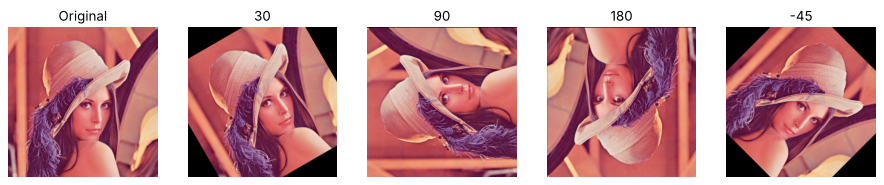

In [8]:
angulos = [30, 90, 180, -45]

fig, ax = plt.subplots(1,5,figsize=(14,3))
ax[0].imshow(img_rgb); ax[0].set_title("Original")
for i in range(4):
    M = cv2.getRotationMatrix2D(centro, angulos[i], 1.0)
    rot = cv2.warpAffine(img_rgb, M, (ancho, alto))
    ax[i+1].imshow(rot)
    ax[i+1].set_title(str(angulos[i]))
for x in ax:
    x.axis('off')
plt.show()

Con 90 y 180 grados la imagen cabe entera. Con 30 y −45 se pierden las esquinas y salen zonas negras donde no hay ningún píxel de la original.

## 2. Negativo de la imagen

En el negativo cada píxel se cambia por su valor opuesto. Con 8 bits hay 256 niveles, así que queda s = 255 − r. Con NumPy basta con restar a 255, y en color se hace en los tres canales a la vez.

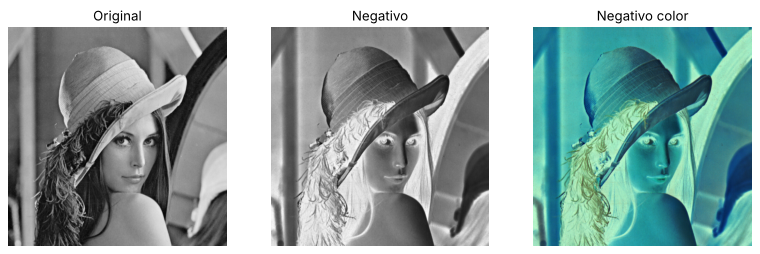

In [9]:
negativo = 255 - gris
negativo_color = 255 - img_rgb

fig, ax = plt.subplots(1,3,figsize=(12,4))
ax[0].imshow(gris, cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(negativo, cmap="gray"); ax[1].set_title("Negativo")
ax[2].imshow(negativo_color); ax[2].set_title("Negativo color")
for x in ax:
    x.axis('off')
plt.show()

Compruebo que da lo mismo que bitwise_not de OpenCV y miro un píxel:

In [10]:
neg_cv = cv2.bitwise_not(gris)
print("Iguales: ", np.array_equal(negativo, neg_cv))
print("Valor pixel original: ", gris[100,100])
print("Valor pixel negativo: ", negativo[100,100])
print("min ", negativo.min())
print("max ", negativo.max())

Iguales:  True
Valor pixel original:  102
Valor pixel negativo:  153
min  10
max  230


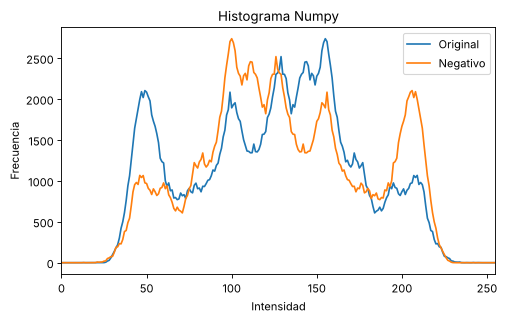

In [11]:
counts, bins = np.histogram(gris, bins=256, range=(0,255))
counts_neg, bins = np.histogram(negativo, bins=256, range=(0,255))

plt.figure(figsize=(7,4))
plt.plot(counts, label="Original")
plt.plot(counts_neg, label="Negativo")
plt.title("Histograma Numpy")
plt.xlim([0,255])
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

El píxel 100,100 pasa de 102 a 153 y la imagen pasa de ir de 25 a 245 a ir de 10 a 230. El histograma del negativo es el de la original dado la vuelta, como en un espejo.

## 3. Imagen umbralizada

Para umbralizar se elige un nivel de gris. Los píxeles que están en ese nivel o por debajo pasan a negro y los que están por encima a blanco, y queda una imagen binaria. Primero pruebo con 50, 100 y 150 usando threshold con THRESH_BINARY.

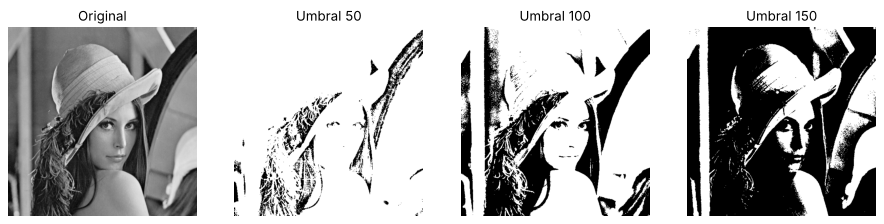

In [12]:
umbrales = [50, 100, 150]

fig, ax = plt.subplots(1,4,figsize=(14,4))
ax[0].imshow(gris, cmap="gray"); ax[0].set_title("Original")
for i in range(3):
    t, bw = cv2.threshold(gris, umbrales[i], 255, cv2.THRESH_BINARY)
    ax[i+1].imshow(bw, cmap="gray")
    ax[i+1].set_title("Umbral " + str(umbrales[i]))
for x in ax:
    x.axis('off')
plt.show()

Con 50 casi todo sale blanco y con 150 casi todo negro, así que el umbral bueno está por el medio. Lo normal es ponerlo en el valle del histograma, y para calcularlo solo está el método de Otsu. Se pone 0 como umbral, se añade THRESH_OTSU y la función devuelve el umbral que ha usado.

In [13]:
t, otsu = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("umbral: ", t)
print("min ", otsu.min())
print("max ", otsu.max())
print("Porcentaje de blancos: ", np.mean(otsu == 255) * 100)

umbral:  117.0
min  0
max  255
Porcentaje de blancos:  58.36143493652344


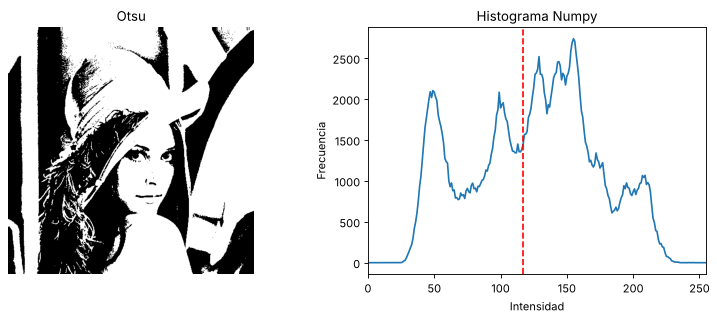

In [14]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.imshow(otsu, cmap="gray")
plt.title("Otsu")
plt.axis('off')

plt.subplot(1,2,2)
plt.plot(counts)
plt.axvline(t, color="r", linestyle="--")
plt.title("Histograma Numpy")
plt.xlim([0,255])
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")
plt.show()

Otsu da 117 y deja el 58 % de la imagen en blanco. Lena no tiene un valle claro porque no es un objeto sobre un fondo, así que Otsu elige el valor que mejor separa los píxeles en dos grupos. Aun así se distinguen bien la cara, el sombrero y el pelo.

## 4. Imagen ecualizada

La ecualización intenta que el histograma quede lo más plano posible, o sea, que el histograma acumulado sea casi una recta. Así se reparten los niveles por todo el rango y hay más contraste. Uso equalizeHist.

In [15]:
gris_eq = cv2.equalizeHist(gris)
a = np.array(gris_eq)
print("min ", a.min())
print("max ", a.max())
print("media ", a.mean())
print("std ", a.std())

min  0
max  255
media  128.27414321899414
std  73.58963343801972


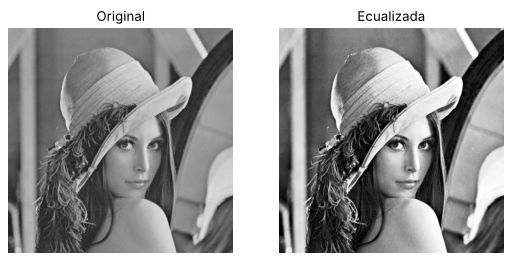

In [16]:
fig, ax = plt.subplots(1,2,figsize=(8,4))
ax[0].imshow(gris, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Original")
ax[1].imshow(gris_eq, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Ecualizada")
for x in ax:
    x.axis('off')
plt.show()

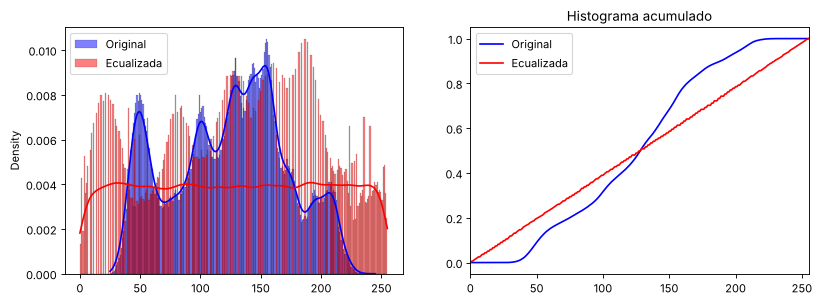

In [17]:
counts_eq, bins = np.histogram(gris_eq, bins=256, range=(0,255))
acum = np.cumsum(counts) / gris.size
acum_eq = np.cumsum(counts_eq) / gris.size

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
sns.histplot(gris.ravel(), bins=256, binrange=(0,255), stat="density", kde=True, color="b", label="Original")
sns.histplot(gris_eq.ravel(), bins=256, binrange=(0,255), stat="density", kde=True, color="r", label="Ecualizada")
plt.legend()

plt.subplot(1,2,2)
plt.plot(acum, color="b", label="Original")
plt.plot(acum_eq, color="r", label="Ecualizada")
plt.title("Histograma acumulado")
plt.xlim([0,255])
plt.legend()
plt.show()

Ahora va de 0 a 255 y la desviación típica sube de 47,9 a 73,6, así que hay bastante más contraste. El histograma ecualizado queda casi plano y el acumulado casi recto. No sale perfectamente plano porque solo se pueden mover niveles enteros de sitio, no partirlos.

Para ver de dónde salen los valores nuevos la hago también a mano con el histograma acumulado. Cada nivel r pasa a 255 por la suma del histograma normalizado hasta r. Lo guardo en una tabla de 256 valores y la aplico a toda la imagen.

In [18]:
p = counts / gris.size
acum = np.cumsum(p)
tabla = np.round(255 * acum).astype(np.uint8)
gris_eq2 = tabla[gris]

print("Nivel 25 pasa a ", tabla[25])
print("Nivel 124 pasa a ", tabla[124])
print("Nivel 245 pasa a ", tabla[245])
print("Igual que equalizeHist: ", np.array_equal(gris_eq2, gris_eq))

Nivel 25 pasa a  0
Nivel 124 pasa a  118
Nivel 245 pasa a  255
Igual que equalizeHist:  True


Sale exactamente igual que equalizeHist. El nivel más oscuro pasa a 0, el más claro a 255 y el 124, que está cerca de la media, a 118.

En una imagen en color hay que ecualizar solo la luminancia. Para verlo paso la imagen a YCrCb, ecualizo solo la Y y la vuelvo a pasar a RGB, y lo comparo con ecualizar R, G y B por separado.

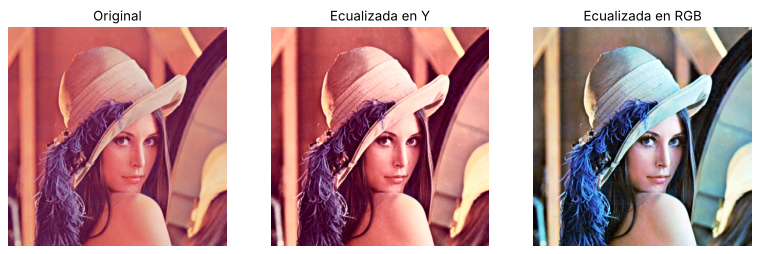

In [19]:
ycrcb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)
ycrcb[:,:,0] = cv2.equalizeHist(ycrcb[:,:,0])
color_eq = cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2RGB)

R = cv2.equalizeHist(img_rgb[:,:,0])
G = cv2.equalizeHist(img_rgb[:,:,1])
B = cv2.equalizeHist(img_rgb[...,2])
rgb_eq = np.dstack((R, G, B))

fig, ax = plt.subplots(1,3,figsize=(12,4))
ax[0].imshow(img_rgb); ax[0].set_title("Original")
ax[1].imshow(color_eq); ax[1].set_title("Ecualizada en Y")
ax[2].imshow(rgb_eq); ax[2].set_title("Ecualizada en RGB")
for x in ax:
    x.axis('off')
plt.show()

Ecualizando solo la Y se mantienen los colores de la piel y del fondo. Haciéndolo en cada canal la imagen pierde el tono rojizo y los colores cambian.

## 5. Eliminar el ruido

Lena casi no tiene ruido, así que primero le añado ruido gaussiano, sumando a cada píxel un valor de una normal de media 0 y desviación típica 20, y ruido sal y pimienta, poniendo un 2,5 % de píxeles en negro y otro 2,5 % en blanco. Fijo la semilla para que siempre salga el mismo ruido.

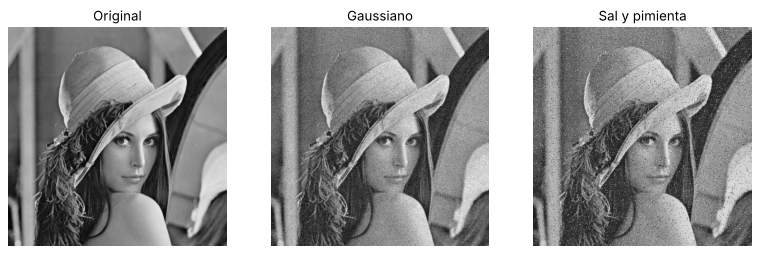

In [20]:
np.random.seed(0)

ruido = np.random.normal(0, 20, gris.shape)
gauss = gris.astype(np.float64) + ruido
gauss = np.clip(gauss, 0, 255).astype(np.uint8)

sal_pim = gris.copy()
r = np.random.rand(gris.shape[0], gris.shape[1])
sal_pim[r < 0.025] = 0
sal_pim[r > 0.975] = 255

fig, ax = plt.subplots(1,3,figsize=(12,4))
ax[0].imshow(gris, cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(gauss, cmap="gray"); ax[1].set_title("Gaussiano")
ax[2].imshow(sal_pim, cmap="gray"); ax[2].set_title("Sal y pimienta")
for x in ax:
    x.axis('off')
plt.show()

Pruebo cinco filtros. Tres son de convolución y los aplico con filter2D: la media de 3x3, la máscara dividida entre 10 y la dividida entre 16, que es la gaussiana. Los otros dos no son lineales: la mediana de 3x3 con medianBlur y el filtro del bicho raro, que cambia un píxel por la media de sus 8 vecinos solo si se diferencia de ella más de un umbral U. Este último lo hago con NumPy porque OpenCV no lo trae.

In [21]:
h_media = np.ones((3,3)) / 9
h_10 = np.array([[1,1,1],
                 [1,2,1],
                 [1,1,1]]) / 10
h_16 = np.array([[1,2,1],
                 [2,4,2],
                 [1,2,1]]) / 16
h_vecinos = np.array([[1,1,1],
                      [1,0,1],
                      [1,1,1]]) / 8
U = 60

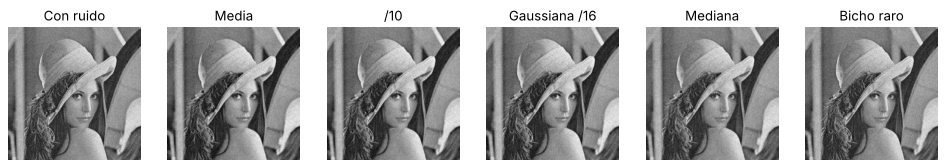

In [22]:
media_g = cv2.filter2D(gauss, -1, h_media)
f10_g = cv2.filter2D(gauss, -1, h_10)
f16_g = cv2.filter2D(gauss, -1, h_16)
mediana_g = cv2.medianBlur(gauss, 3)
vecinos = cv2.filter2D(gauss, -1, h_vecinos)
dif = np.abs(gauss.astype(int) - vecinos.astype(int))
bicho_g = np.where(dif > U, vecinos, gauss).astype(np.uint8)

fig, ax = plt.subplots(1,6,figsize=(15,3))
ax[0].imshow(gauss, cmap="gray"); ax[0].set_title("Con ruido")
ax[1].imshow(media_g, cmap="gray"); ax[1].set_title("Media")
ax[2].imshow(f10_g, cmap="gray"); ax[2].set_title("/10")
ax[3].imshow(f16_g, cmap="gray"); ax[3].set_title("Gaussiana /16")
ax[4].imshow(mediana_g, cmap="gray"); ax[4].set_title("Mediana")
ax[5].imshow(bicho_g, cmap="gray"); ax[5].set_title("Bicho raro")
for x in ax:
    x.axis('off')
plt.show()

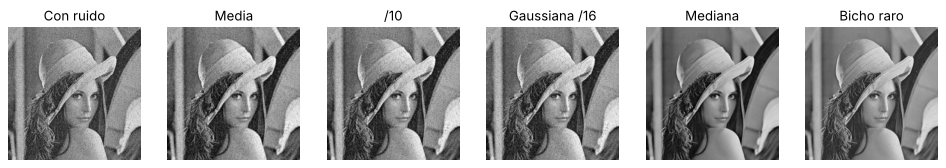

In [23]:
media_sp = cv2.filter2D(sal_pim, -1, h_media)
f10_sp = cv2.filter2D(sal_pim, -1, h_10)
f16_sp = cv2.filter2D(sal_pim, -1, h_16)
mediana_sp = cv2.medianBlur(sal_pim, 3)
vecinos = cv2.filter2D(sal_pim, -1, h_vecinos)
dif = np.abs(sal_pim.astype(int) - vecinos.astype(int))
bicho_sp = np.where(dif > U, vecinos, sal_pim).astype(np.uint8)

fig, ax = plt.subplots(1,6,figsize=(15,3))
ax[0].imshow(sal_pim, cmap="gray"); ax[0].set_title("Con ruido")
ax[1].imshow(media_sp, cmap="gray"); ax[1].set_title("Media")
ax[2].imshow(f10_sp, cmap="gray"); ax[2].set_title("/10")
ax[3].imshow(f16_sp, cmap="gray"); ax[3].set_title("Gaussiana /16")
ax[4].imshow(mediana_sp, cmap="gray"); ax[4].set_title("Mediana")
ax[5].imshow(bicho_sp, cmap="gray"); ax[5].set_title("Bicho raro")
for x in ax:
    x.axis('off')
plt.show()

Para compararlos calculo el error medio entre cada imagen y la original sin ruido, que es la media de la diferencia en valor absoluto. Cuanto más bajo, más se parece a la original.

In [24]:
g = gris.astype(int)

print("Ruido gaussiano")
print("Sin filtrar: ", round(np.mean(np.abs(g - gauss.astype(int))), 2))
print("Media: ", round(np.mean(np.abs(g - media_g.astype(int))), 2))
print("/10: ", round(np.mean(np.abs(g - f10_g.astype(int))), 2))
print("Gaussiana /16: ", round(np.mean(np.abs(g - f16_g.astype(int))), 2))
print("Mediana: ", round(np.mean(np.abs(g - mediana_g.astype(int))), 2))
print("Bicho raro: ", round(np.mean(np.abs(g - bicho_g.astype(int))), 2))
print("")
print("Ruido sal y pimienta")
print("Sin filtrar: ", round(np.mean(np.abs(g - sal_pim.astype(int))), 2))
print("Media: ", round(np.mean(np.abs(g - media_sp.astype(int))), 2))
print("/10: ", round(np.mean(np.abs(g - f10_sp.astype(int))), 2))
print("Gaussiana /16: ", round(np.mean(np.abs(g - f16_sp.astype(int))), 2))
print("Mediana: ", round(np.mean(np.abs(g - mediana_sp.astype(int))), 2))
print("Bicho raro: ", round(np.mean(np.abs(g - bicho_sp.astype(int))), 2))

Ruido gaussiano
Sin filtrar:  15.91
Media:  6.53
/10:  6.52
Gaussiana /16:  6.74
Mediana:  7.53
Bicho raro:  15.7

Ruido sal y pimienta
Sin filtrar:  6.37
Media:  7.79
/10:  7.6
Gaussiana /16:  7.45
Mediana:  2.54
Bicho raro:  0.69


Con ruido gaussiano los mejores son los filtros de convolución, que bajan el error de casi 16 a unos 6,5, aunque la imagen queda algo borrosa. El bicho raro casi no hace nada porque todos los píxeles tienen un poco de ruido y casi ninguno pasa el umbral.

Con sal y pimienta es al revés. Los filtros de media lo empeoran porque reparten los puntos blancos y negros entre los vecinos y salen manchas. La mediana baja el error a 2,5 y el bicho raro a 0,7, porque solo cambia los píxeles que son muy distintos a sus vecinos y el resto lo deja igual.

O sea, hay que elegir el filtro según el tipo de ruido que tenga la imagen.

## Conclusiones

La rotación cambia la posición de los píxeles pero no su valor, y hay que hacerla al revés para que no queden huecos. El negativo y la umbralización cambian el valor de cada píxel por separado. El negativo es solo 255 menos el valor, y en la umbralización el resultado depende mucho del umbral que se elija. La ecualización estira el rango de 25 a 245 hasta 0 a 255 y mejora el contraste, y en color hay que hacerla sobre la luminancia. Para el ruido no hay un filtro que valga para todo: para el gaussiano van mejor los de media y para el sal y pimienta la mediana o el bicho raro.